# Figure S15: Fine-mapping annotation enrichment

Functional annotation enrichment estimates and confidence intervals from the PIP regression models.


## Run the notebook

Use the R kernel. Start in the repository root. Set `QTL_INPUT_ROOT` to the
source result tables and `QTL_SUSIE_ROOT` to the separate fine-mapping tables.
Set `QTL_PAPER_ROOT` to the local reference directory and `QTL_SOURCE_ROOT`
to the figure checkout. Set these variables in R before running the cells.
Paths can contain spaces.

Run the cells from top to bottom. The cells show input reads, filters, joins,
counts, models, and plot construction. Intermediate objects stay in this R
session. New PDFs and PNGs go to
`notebook_outputs/`. The plotting scripts are in `notebooks/current/`.


## Source scripts

The processing steps below follow these preparation scripts. The source data are not included in Git.

- [s15_enrichment](../current/supplements/S15.R): Fit the original annotation-on-PIP logistic models, adjust P values across slopes, and prepare the enrichment plot input.

The notebook runs the processing in its own cells. The preparation guide lists the original input requirements and missing inputs.


## Setup

Validate the local input paths and load the plot libraries.


In [1]:
# Shared setup for the figure notebooks.
suppressPackageStartupMessages({
  library(tidyverse)
  library(patchwork)
})
if (requireNamespace("showtext", quietly = TRUE)) showtext::showtext_auto(FALSE)

paper_root <- Sys.getenv("QTL_PAPER_ROOT")
source_root <- Sys.getenv("QTL_SOURCE_ROOT", getwd())
input_root <- Sys.getenv("QTL_INPUT_ROOT", source_root)
susie_root <- Sys.getenv("QTL_SUSIE_ROOT", input_root)
repo_root <- getwd()
notebook_output <- Sys.getenv("QTL_NOTEBOOK_OUTPUT", file.path(getwd(), "notebook_outputs"))
input_records <- new.env(parent = emptyenv())

checked_input <- function(root, relative, variable) {
  if (!nzchar(root)) stop("Set ", variable, " before you run this notebook.", call. = FALSE)
  if (grepl("^(gs|s3|https?)://", root)) {
    stop("Input localization error: ", variable, " must be a local directory.", call. = FALSE)
  }
  if (grepl("[.]rds([.]gz)?$", relative, ignore.case = TRUE)) {
    stop("Saved RDS inputs are not used by these notebooks: ", relative, call. = FALSE)
  }
  path <- file.path(root, relative)
  if (!file.exists(path) || dir.exists(path) || file.access(path, 4) != 0) {
    stop("Missing or unreadable input: ", relative, ". Check ", variable, ".", call. = FALSE)
  }
  path <- normalizePath(path, mustWork = TRUE)
  key <- paste(variable, relative, sep = ":")
  hash <- unname(tools::md5sum(path))
  previous <- input_records[[key]]
  if (!is.null(previous) && !identical(previous$md5, hash)) {
    stop("Input changed during notebook execution: ", relative, call. = FALSE)
  }
  if (is.null(previous)) input_records[[key]] <- list(root = variable, path = relative, md5 = hash)
  path
}
paper_file <- function(relative) checked_input(paper_root, relative, "QTL_PAPER_ROOT")
source_file <- function(relative) checked_input(source_root, relative, "QTL_SOURCE_ROOT")
input_file <- function(relative) checked_input(input_root, relative, "QTL_INPUT_ROOT")
susie_file <- function(relative) checked_input(susie_root, relative, "QTL_SUSIE_ROOT")
repo_file <- function(relative) checked_input(repo_root, relative, "QTL_REPO_ROOT")
output_file <- function(relative) {
  path <- file.path(notebook_output, relative)
  dir.create(dirname(path), recursive = TRUE, showWarnings = FALSE)
  path
}

save_plot <- function(plot, name, width_mm = 180, height_mm = 130) {
  message("Export aggregate plot: ", name)
  for (extension in c("pdf", "png")) {
    ggplot2::ggsave(output_file(paste0(name, ".", extension)), plot,
                   width = width_mm, height = height_mm, units = "mm", dpi = 180,
                   device = if (extension == "pdf") grDevices::cairo_pdf else "png",
                   bg = "white", limitsize = FALSE)
  }
  invisible(plot)
}

display_image <- function(path) {
  capture <- getOption("qtl.notebook.display")
  if (is.function(capture)) capture(path) else IRdisplay::display_png(file = path)
  invisible(NULL)
}
show_reference <- function(number) {
  path <- paper_file(paste0("output/Science_submission_package_20261102/Figures/Figure", number, ".png"))
  message("Display reference Figure ", number, ".")
  display_image(path)
}

theme_set(theme_classic(base_size = 9) +
            theme(plot.title = element_blank(), plot.subtitle = element_blank(),
                  legend.title = element_blank(), panel.grid = element_blank()))
options(repr.plot.width = 10, repr.plot.height = 7, repr.plot.res = 150)
message("Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.")
# Local source-result inputs and memory-only intermediate objects.
prep_root <- function(name) {
  value <- switch(name, paper = paper_root, source = source_root,
                  input = input_root, susie = susie_root,
                  stop("Unknown source root: ", name, call. = FALSE))
  if (!nzchar(value)) stop("Set the local ", name, " root before running the notebook.", call. = FALSE)
  value
}
.prep_root <- prep_root
prep_input <- function(root_name, relative) {
  variable <- c(paper = "QTL_PAPER_ROOT", source = "QTL_SOURCE_ROOT",
                input = "QTL_INPUT_ROOT", susie = "QTL_SUSIE_ROOT")[[root_name]]
  checked_input(prep_root(root_name), relative, variable)
}
prep_input_any <- function(root_name, candidates) {
  for (relative in candidates) {
    if (file.exists(file.path(prep_root(root_name), relative))) return(prep_input(root_name, relative))
  }
  stop("Missing source input under ", root_name, ": ", paste(candidates, collapse = ", "), call. = FALSE)
}
prep_input_file <- function(variable, fallback_root = "input", relative) {
  path <- Sys.getenv(variable)
  if (!nzchar(path)) return(prep_input_any(fallback_root, relative))
  checked_input(dirname(path), basename(path), paste0("env:", variable))
}
# Resolve recorded paths for the input-unchanged check. Records contain no
# machine-specific directory names; explicit file overrides retain their key.
recorded_input_path <- function(record) {
  if (startsWith(record$root, "env:")) return(Sys.getenv(sub("^env:", "", record$root)))
  root <- switch(record$root, QTL_PAPER_ROOT = paper_root,
                 QTL_SOURCE_ROOT = source_root, QTL_INPUT_ROOT = input_root,
                 QTL_SUSIE_ROOT = susie_root, QTL_REPO_ROOT = repo_root,
                 stop("Unknown recorded input root: ", record$root, call. = FALSE))
  file.path(root, record$path)
}

# These functions read the tracked result-table manifest. Each notebook starts
# with an empty memory store. An existing file cannot skip a calculation.
prep_result_runtime <- function(figure, envir = parent.frame()) {
  manifest <- readr::read_tsv(repo_file(file.path(figure, "inputs.tsv")),
    col_types = cols(.default = col_character()), na = c("", "-"), show_col_types = FALSE)
  computed <- new.env(parent = emptyenv())
  input_files <- function(key) {
    rows <- manifest[manifest$key == key, , drop = FALSE]
    if (!nrow(rows)) stop("Unknown result-table key: ", key, call. = FALSE)
    rows$path <- map_chr(rows$local_subpath, function(relative) {
      if (key == "clingen") {
        files <- list.files(file.path(prep_root("input"), relative), pattern = "[.]parquet$", full.names = FALSE)
        if (!length(files)) stop("No ClinGen parquet input under ", relative, call. = FALSE)
        return(prep_input("input", file.path(relative, sort(files)[1])))
      }
      candidates <- unique(c(relative, sub("splicing_SusieMerged[.]annotated", "splicing_SusieMerged..annotated", relative)))
      prep_input_any("input", candidates)
    })
    rows
  }
  input_path <- function(key) {
    rows <- input_files(key)
    if (nrow(rows) != 1L) stop("Expected one input for ", key, call. = FALSE)
    rows$path
  }
  load_input <- function(key, reader = data.table::fread, ..., attach_meta = TRUE) {
    rows <- input_files(key)
    metadata <- setdiff(names(rows), c("key", "local_subpath", "gs_uri", "source_repo", "source_workflow", "path"))
    map_dfr(seq_len(nrow(rows)), function(i) {
      data <- as_tibble(reader(rows$path[i], ...))
      if (attach_meta) for (column in metadata) if (!is.na(rows[[column]][i])) data[[column]] <- rows[[column]][i]
      data
    })
  }
  build_or_cache <- function(name, expr, refresh = FALSE) {
    if (!refresh && exists(name, envir = computed, inherits = FALSE)) return(computed[[name]])
    message("Calculate ", figure, "/", name, " from source result tables")
    value <- force(expr)
    computed[[name]] <- value
    value
  }
  for (name in c("input_files", "input_path", "load_input", "build_or_cache")) assign(name, get(name), envir = envir)
  invisible(computed)
}


Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.


## Define annotation expansion and logistic models

Keep every fine-mapped variant in the background, including variants with no VEP consequence. Expand consequences into binary flags. For each flag that varies, fit annotation membership against PIP with a binomial logistic model.


In [2]:
# =============================================================================
# The model behind fig1/enrichment_glm.R. Defines only -- sourcing this runs
# nothing -- so tests can exercise the fit without the controlled-access tables.
# =============================================================================

# The genuine logical annotation flags, named rather than picked up with
# `where(is.logical)`. They cannot be found by type: in the SPLICING table tss,
# gene_name, distTSS, Constrained and lof.pLI are NA for every single row, so
# fread types all five as logical and `where(is.logical)` sweeps them in as
# annotations. One of them is then all-NA after the pivot, which leaves glm()
# no response to fit and aborts the run. Naming the columns also means a renamed
# or missing flag is an error here instead of an annotation that quietly
# disappears from the results, which is how two UTR annotations once went
# missing from panel H (see NOTES.md).
CCRE_FLAG_COLS <- c("CTCF.only", "CTCF.bound", "pELS", "DNase.H3K4me3",
                    "dELS", "PLS", "FANTOM5")

# Where variants with no VEP consequence are parked. They must stay in the
# table -- a variant with no consequence is still a background variant for
# every cCRE flag, and dropping the rows would quietly shrink the denominator
# of every other fit -- but "no consequence recorded" is not an annotation to
# regress, so the column is removed once the one-hot pivot has happened.
NO_CONSEQUENCE <- ".no_consequence_recorded"

# One row per (variant, PIP, annotation): the cCRE flags arrive as logical
# columns and VEP consequences as one comma-separated string, so the
# consequences are one-hot expanded and then folded in with the flags. Returns
# broom::tidy() output per annotation, i.e. an (Intercept) row and a pip row.
GlmAnnotationEnrichment <- function(path) {
  d <- data.table::fread(path,
                         select = c("variant", "pip", "consequence", CCRE_FLAG_COLS))

  missing <- setdiff(CCRE_FLAG_COLS, names(d))
  if (length(missing))
    stop("annotation flags absent from ", basename(path), ": ",
         paste(missing, collapse = ", "))
  not_logical <- CCRE_FLAG_COLS[!vapply(d[, ..CCRE_FLAG_COLS], is.logical, logical(1))]
  if (length(not_logical))
    stop("annotation flags are not logical in ", basename(path), ": ",
         paste(not_logical, collapse = ", "))

  message("  ", nrow(d), " rows, ", dplyr::n_distinct(d$variant), " distinct variants")

  d %>%
    select(variant, pip, where(is.logical), consequence) %>%
    separate_rows(consequence, sep = ",") %>%
    # NA, "" and VEP's "." placeholder all mean the same thing. The empty string
    # matters in its own right: pivot_wider cannot create a column named "" and
    # errors out, whereas NA silently becomes a column called "NA".
    mutate(consequence = ifelse(is.na(consequence) | consequence %in% c("", "."),
                                NO_CONSEQUENCE, consequence)) %>%
    mutate(value = TRUE) %>%
    distinct() %>%
    pivot_wider(names_from = consequence, values_from = value, values_fill = FALSE) %>%
    select(-any_of(NO_CONSEQUENCE)) %>%
    pivot_longer(where(is.logical)) %>%
    group_by(name) %>%
    # An annotation that is TRUE for every variant, or FALSE for every variant,
    # has nothing to regress; glm() errors rather than returning a null fit.
    filter(dplyr::n_distinct(value) == 2) %>%
    do(broom::tidy(glm(value ~ pip, family = "binomial", data = .))) %>%
    arrange(desc(estimate))
}

# Adjust all annotation-by-assay PIP slopes together, before the plot subset.
s15_model_summaries <- function(fits) {
  fits %>% filter(term == "pip") %>% ungroup() %>%
    mutate(padj = p.adjust(p.value, method = "fdr"),
      conf.low = estimate - 1.96 * std.error,
      conf.high = estimate + 1.96 * std.error,
      separated = std.error > 10) %>% arrange(desc(estimate))
}

# These labels select the same twelve annotations as Figure 1H.
PANEL_ANNOTATION_LABELS <- c(
  splice_donor_variant = "Splice donor", splice_acceptor_variant = "Splice acceptor",
  stop_gained = "Stop gained", missense_variant = "Missense",
  frameshift_variant = "Frameshift", start_lost = "Start lost",
  PLS = "Promoter", dELS = "Distal enhancer", `5_prime_UTR_variant` = "5' UTR",
  `3_prime_UTR_variant` = "3' UTR", pELS = "Proximal enhancer",
  splice_region_variant = "Splice region")

variant_functional_groups <- tibble::tribble(
  ~name, ~functional_group,
  "3_prime_UTR_variant", "Regulatory Annotation",
  "5_prime_UTR_variant", "Regulatory Annotation",
  "CTCF.bound", "Regulatory Annotation",
  "DNase.H3K4me3", "Regulatory Annotation",
  "FANTOM5", "Regulatory Annotation",
  "PLS", "Regulatory Annotation", "pELS", "Regulatory Annotation", "dELS", "Regulatory Annotation",
  "coding_sequence_variant", "Coding Annotation", "frameshift_variant", "Coding Annotation",
  "inframe_deletion", "Coding Annotation", "inframe_insertion", "Coding Annotation",
  "missense_variant", "Coding Annotation", "synonymous_variant", "Coding Annotation",
  "start_lost", "Coding Annotation", "stop_gained", "Coding Annotation",
  "stop_lost", "Coding Annotation", "stop_retained_variant", "Coding Annotation",
  "splice_acceptor_variant", "Splice Annotation", "splice_donor_variant", "Splice Annotation",
  "splice_donor_5th_base_variant", "Splice Annotation", "splice_donor_region_variant", "Splice Annotation",
  "splice_region_variant", "Splice Annotation", "splice_polypyrimidine_tract_variant", "Splice Annotation",
  "non_coding_transcript_exon_variant", "Noncoding RNA", "non_coding_transcript_variant", "Noncoding RNA",
  "mature_miRNA_variant", "Noncoding RNA", "downstream_gene_variant", "Intronic/Intergenic",
  "upstream_gene_variant", "Intronic/Intergenic", "intron_variant", "Intronic/Intergenic",
  "intergenic_variant", "Intronic/Intergenic")

s15_plot_data <- function(results) {
  data <- results %>% filter(name %in% names(PANEL_ANNOTATION_LABELS)) %>%
    left_join(variant_functional_groups, by = "name", relationship = "many-to-one") %>%
    mutate(annotation_clean = unname(PANEL_ANNOTATION_LABELS[name])) %>%
    group_by(functional_group) %>% mutate(row = as.numeric(factor(annotation_clean))) %>% ungroup()
  stopifnot(!anyNA(data$functional_group))
  if (any(data$separated)) {
    message("Exclude selected annotation fits with no finite maximum-likelihood slope.")
    data <- filter(data, !separated)
  }
  data %>% mutate(odds_ratio = exp(estimate), lower = exp(conf.low), upper = exp(conf.high),
    type = factor(type, c("eQTL", "sQTL", "pQTL")), significant = padj < 0.05)
}


## Fit the three source annotation tables

Read the original combined eQTL, sQTL and pQTL annotation tables. Keep the PIP slope from each model. Adjust P values across all annotation and assay slopes with the Benjamini–Hochberg method before selecting plot annotations. Use estimate ± 1.96 × standard error for the Wald interval.


In [3]:
annotation_inputs <- read_tsv(repo_file("Fig1/inputs.tsv"),
  col_types = cols(.default = col_character()), show_col_types = FALSE) %>% filter(key == "annot")
stopifnot(nrow(annotation_inputs) == 3L, setequal(annotation_inputs$Assay, c("eQTL", "sQTL", "pQTL")))
fits <- map2_dfr(annotation_inputs$local_subpath, annotation_inputs$Assay, function(path, assay) {
  message("Fit annotation enrichment: ", assay)
  alternatives <- unique(c(path, sub("splicing_SusieMerged[.]annotated", "splicing_SusieMerged..annotated", path)))
  GlmAnnotationEnrichment(prep_input_any("input", alternatives)) %>% mutate(type = assay)
})
model_summaries <- s15_model_summaries(fits)
enrichment <- s15_plot_data(model_summaries)
stopifnot(all(is.finite(enrichment$odds_ratio)), all(enrichment$lower > 0),
  all(enrichment$upper >= enrichment$lower), !any(enrichment$separated))
message("Fitted source annotation models and calculated adjusted P values and Wald intervals.")


Fit annotation enrichment: eQTL


  844442 rows, 646283 distinct variants


Fit annotation enrichment: sQTL


  254361 rows, 218530 distinct variants


Fit annotation enrichment: pQTL


  60636 rows, 59027 distinct variants


Fitted source annotation models and calculated adjusted P values and Wald intervals.


## Draw the annotation odds ratios

Points show odds ratios for PIP = 1 versus PIP = 0. Bars show the 95% Wald intervals. The dashed line marks an odds ratio of one. Opacity uses the adjusted P value.


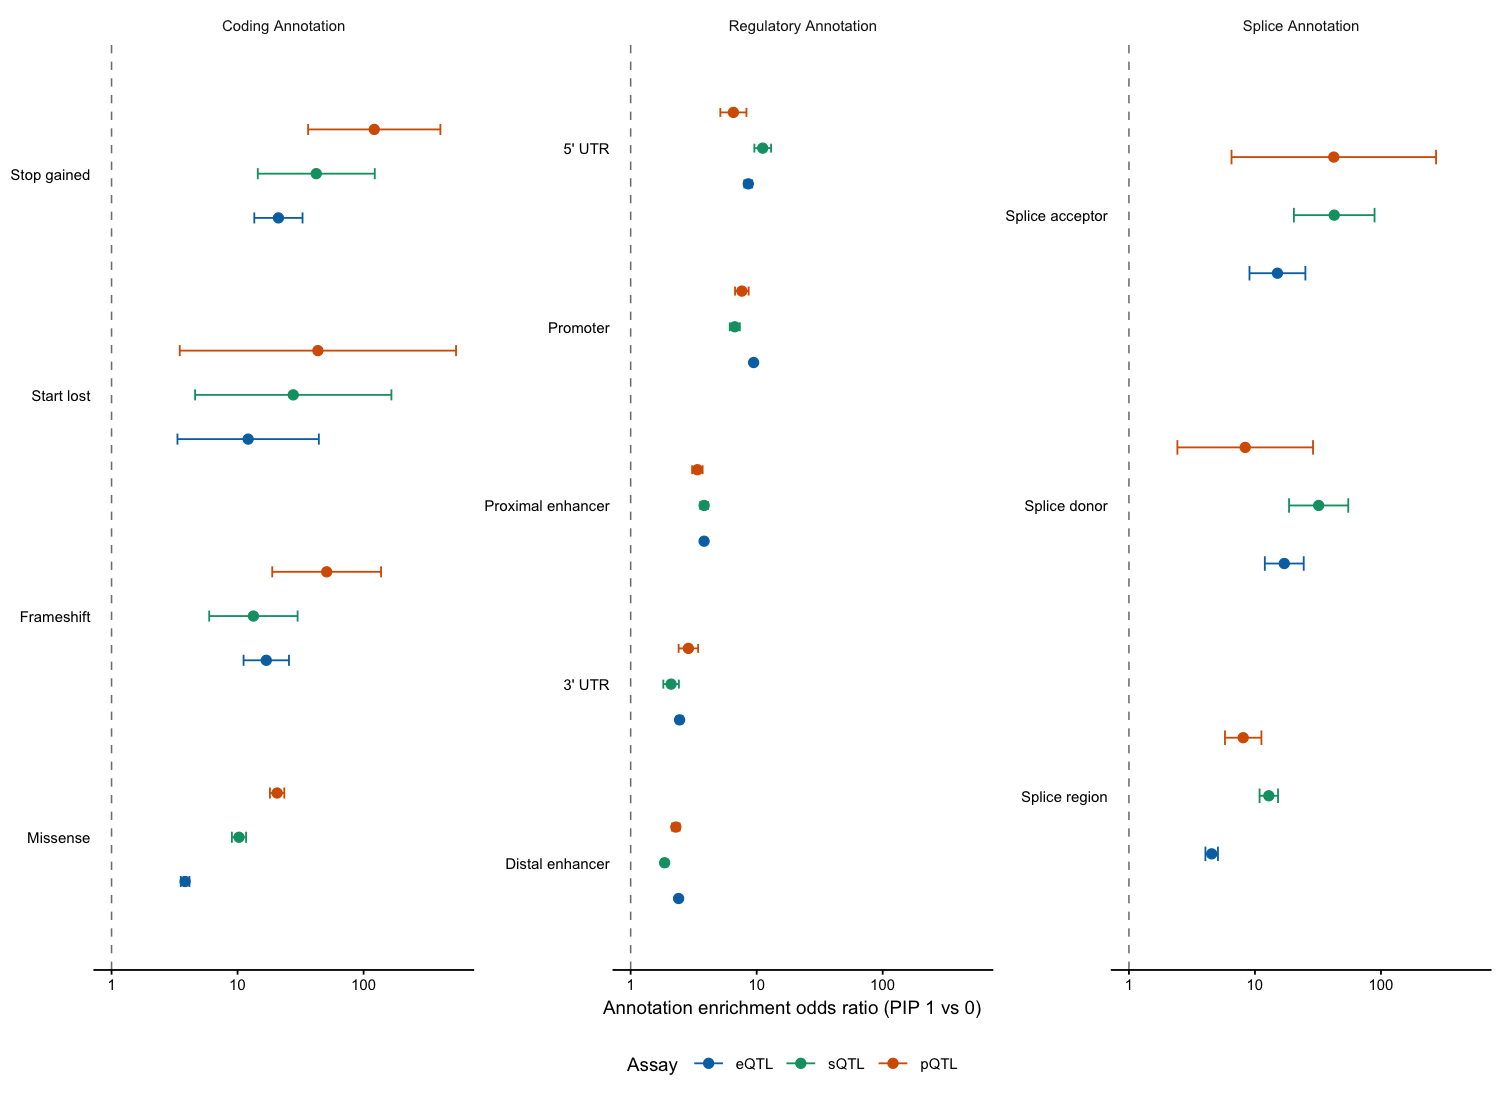

In [4]:
dodge <- position_dodge(width = 0.6)
figure <- ggplot(enrichment, aes(odds_ratio, reorder(annotation_clean, odds_ratio), colour = type, alpha = significant)) +
  geom_vline(xintercept = 1, linetype = "dashed", colour = "grey50", linewidth = 0.35) +
  geom_errorbar(aes(xmin = lower, xmax = upper), orientation = "y", width = 0.15, position = dodge) +
  geom_point(size = 2, position = dodge) +
  facet_wrap(~functional_group, scales = "free_y", nrow = 1) +
  scale_x_log10(labels = scales::label_number()) +
  scale_colour_manual(values = c(eQTL = "#0072B2", sQTL = "#009E73", pQTL = "#D55E00"), name = "Assay") +
  scale_alpha_manual(values = c(`FALSE` = 0.3, `TRUE` = 1),
    labels = c(`FALSE` = "Adjusted P ≥ 0.05", `TRUE` = "Adjusted P < 0.05"), name = NULL) +
  labs(x = "Annotation enrichment odds ratio (PIP 1 vs 0)", y = NULL) +
  theme_classic(base_size = 9) +
  theme(strip.background = element_blank(), legend.position = "bottom",
    axis.line.y = element_blank(), axis.ticks.y = element_blank())
if (n_distinct(enrichment$significant) == 1L) figure <- figure + guides(alpha = "none")
print(figure)


## Save aggregate outputs

Save the plot and the fitted model summaries. Fine-mapping and variant annotation are source-result boundaries.


In [5]:
save_plot(figure, "supplements/S15", 184, 120)
readr::write_tsv(enrichment %>% select(type, functional_group, annotation_clean, estimate, std.error,
  conf.low, conf.high, odds_ratio, lower, upper, p.value, padj),
  output_file("supplements/S15_model_summaries.tsv"))
readr::write_tsv(model_summaries, output_file("supplements/S15_all_annotation_models.tsv"))


Export aggregate plot: supplements/S15
